# 05 · Research improvements: survivorship, which-not-when, walk-forward, homework borrowings

This notebook reads the tables produced by the second development wave (OPM SD1/SD2/SD3 changes):

| Topic | Table | Origin |
|---|---|---|
| Survivorship bias: current members vs point-in-time universe | `survivorship.parquet` | roadmap R1, HW1 Q1 change tables |
| Model variants: pooled vs cross-sectional vs per-family vs ranking | `model_comparison.parquet` | README §8 diagnosis |
| Book composition (exclude breakouts / `mgmt_change`?) | `composition.parquet` | README §8 diagnosis |
| Walk-forward yearly refits, stitched OOS track record | `walkforward.parquet`, `walkforward_equity.parquet` | roadmap R2 |
| Holding period by family | `holding_period.parquet` | HW2 Q3 |
| Uniquely-correct predictions | `uniquely_correct.parquet` | HW3 Q3 |


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
metrics = artifacts.load_metrics()
def show(name):
    df = artifacts.load_frame(name)
    print(f"{name}: {'missing' if df.empty else f'{len(df)} rows'}")
    return df
print(json.dumps({k: metrics.get(k) for k in ("versions", "walkforward")}, indent=1, default=str)[:2500])

{
 "versions": {
  "sklearn": "1.7.2",
  "sklearn_tested_ok": true,
  "lightgbm": "4.6.0",
  "xgboost": "2.1.4",
  "numpy": "1.26.4",
  "pandas": "2.2.3"
 },
 "walkforward": {
  "strategy": "wf_model_top5",
  "model": "lgbm",
  "feature_set": "cs_drop_market",
  "first_year": 2018,
  "purge_days": 16,
  "n_oos_events": 113414,
  "oos_auc": 0.5561422123450439,
  "oos_precision_selected": 0.4828551434569629,
  "oos_base_rate": 0.38073782778140264,
  "start": "2018-01-02",
  "end": "2026-11-13",
  "cagr": 0.1059175957647891,
  "sharpe": 0.47347463338796103,
  "max_drawdown": -0.5937307786437134,
  "total_return": 1.4405609860291175,
  "n_trades": 486,
  "win_rate": 0.5534979423868313,
  "avg_trade_ret": 0.012028304543090233,
  "spy_cagr": 0.1405402556847224,
  "spy_sharpe": 0.7892426176218647,
  "spy_max_drawdown": -0.33699813656214483
 }
}


## 1 · Survivorship bias (R1)

In [3]:
show("survivorship.parquet")

survivorship.parquet: 30 rows


,universe,event_family,events,base_rate,mean_10d,mean_10d_vs_spy
0,current_members_any_date (old behaviour),all,173705,0.375787,0.004176,-0.000233
1,current_members_any_date (old behaviour),earnings_crash,3771,0.418722,0.006993,0.001358
2,current_members_any_date (old behaviour),earnings_down,29862,0.378206,0.005709,-0.000413
3,current_members_any_date (old behaviour),earnings_up,36015,0.384812,0.005826,-0.000268
4,current_members_any_date (old behaviour),momentum_breakout,100801,0.367447,0.002620,-0.000690
5,current_members_any_date (old behaviour),shock_crash,3256,0.462224,0.016773,0.014087
6,point_in_time_all_names,all,147973,0.371575,0.003146,-0.001328
7,point_in_time_all_names,earnings_crash,3743,0.413839,0.003804,-0.001668
8,point_in_time_all_names,earnings_down,26823,0.376431,0.005072,-0.001213
9,point_in_time_all_names,earnings_up,31670,0.382254,0.004797,-0.001289


## 2 · Which, not when: model variants (VALIDATION decides; TEST shown for reference)

In [4]:
show("model_comparison.parquet")

model_comparison.parquet: 23 rows


,variant,learner,feature_set,layout,n_features,val_auc,val_prec_top10,val_prec_top20,val_within_date_corr,val_when_auc,val_base_rate,val_n,test_auc,test_prec_top10,test_prec_top20,test_within_date_corr,test_when_auc,test_base_rate,test_n,seconds
0,a_pooled,rf,pooled,pooled,253,0.546894,0.497071,0.469842,0.050184,0.547662,0.384916,25616,0.532256,0.454329,0.431672,0.049316,0.515149,0.392292,41933,40.0
1,a_pooled,lgbm,pooled,pooled,253,0.498888,0.325654,0.340621,0.032359,0.501878,0.384916,25616,0.532462,0.443358,0.437515,0.059753,0.515758,0.392292,41933,5.5
2,a_pooled,logreg,pooled,pooled,253,0.546479,0.361968,0.392934,0.031590,0.544341,0.384916,25616,0.525956,0.443358,0.424517,0.040114,0.516006,0.392292,41933,10.2
3,a2_pooled_month_wom,rf,pooled_wom,pooled,313,0.557702,0.539633,0.492094,0.049578,0.559152,0.384916,25616,0.535007,0.461006,0.435249,0.049454,0.517765,0.392292,41933,38.4
4,a2_pooled_month_wom,lgbm,pooled_wom,pooled,313,0.511054,0.365482,0.359360,0.041564,0.509438,0.384916,25616,0.529111,0.455998,0.430479,0.057511,0.513744,0.392292,41933,5.6
5,a2_pooled_month_wom,logreg,pooled_wom,pooled,313,0.545204,0.376806,0.390006,0.026415,0.541931,0.384916,25616,0.525968,0.418793,0.429645,0.039375,0.519020,0.392292,41933,12.5
6,b1_cs_keep_market,rf,cs_keep_market,pooled,317,0.545892,0.467786,0.454812,0.048593,0.544009,0.384916,25616,0.535869,0.481994,0.443477,0.050154,0.518192,0.392292,41933,60.4
7,b1_cs_keep_market,lgbm,cs_keep_market,pooled,317,0.500623,0.364701,0.352333,0.029819,0.503952,0.384916,25616,0.530651,0.467684,0.447889,0.052719,0.515426,0.392292,41933,8.1
8,b1_cs_keep_market,logreg,cs_keep_market,pooled,317,0.544890,0.366263,0.384736,0.036113,0.542682,0.384916,25616,0.531638,0.457191,0.442285,0.051780,0.521647,0.392292,41933,17.3
9,b2_cs_drop_market,rf,cs_drop_market,pooled,269,0.554213,0.445920,0.434901,0.053442,0.554205,0.384916,25616,0.545064,0.462199,0.444908,0.054381,0.531633,0.392292,41933,66.5


## 3 · Book composition

In [5]:
show("composition.parquet")

composition.parquet: 48 rows


,kind,name,sample,decision_sample,n_selected,precision,avg_growth_10d,cagr,sharpe,max_drawdown,total_return,n_trades,win_rate,n,base_rate
0,composition,all_families,validation,True,445,0.507865,0.018702,0.244039,0.828336,-0.295353,0.562040,150.0,0.566667,NaN,NaN
1,composition,all_families,test,False,190,0.505263,0.024232,0.060702,0.349580,-0.199376,0.183844,117.0,0.512821,NaN,NaN
2,composition,no_breakout,validation,True,401,0.511222,0.021416,0.276287,0.937184,-0.284429,0.645859,143.0,0.552448,NaN,NaN
3,composition,no_breakout,test,False,161,0.509317,0.024995,0.085615,0.438440,-0.180397,0.265226,103.0,0.514563,NaN,NaN
4,composition,no_mgmt_change,validation,True,441,0.505669,0.018066,0.214212,0.753934,-0.313335,0.486505,150.0,0.560000,NaN,NaN
5,composition,no_mgmt_change,test,False,183,0.497268,0.023681,0.025946,0.229219,-0.199376,0.076113,116.0,0.500000,NaN,NaN
6,composition,no_offering,validation,True,437,0.508009,0.018861,0.230735,0.804654,-0.279498,0.528113,148.0,0.567568,NaN,NaN
7,composition,no_offering,test,False,187,0.508021,0.024403,0.058671,0.342674,-0.199376,0.177364,116.0,0.508621,NaN,NaN
8,composition,no_breakout_no_mgmt,validation,True,400,0.510000,0.021377,0.272359,0.931766,-0.284429,0.635531,142.0,0.549296,NaN,NaN
9,composition,no_breakout_no_mgmt,test,False,155,0.503226,0.024738,0.076955,0.406364,-0.180397,0.236538,102.0,0.509804,NaN,NaN


## 4 · Walk-forward track record (R2)

walkforward.parquet: 114496 rows
walkforward_equity.parquet: 15609 rows


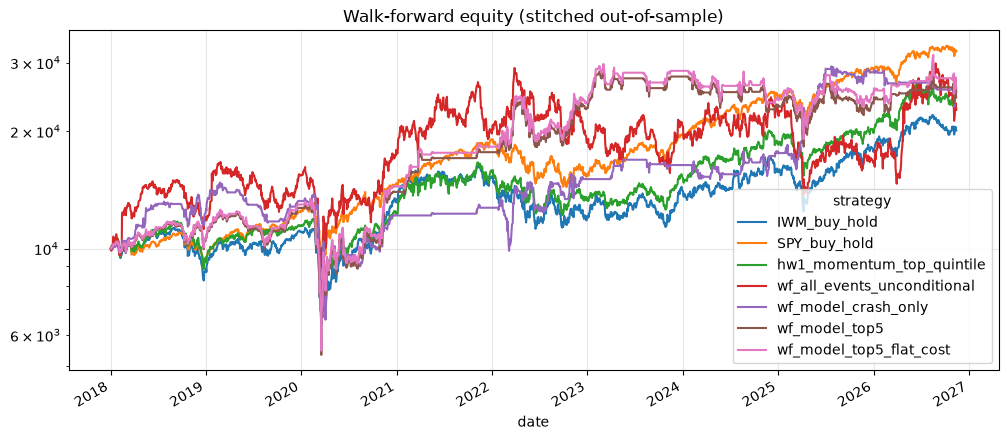

,date,ticker,event_family,edgar_category,cap_bucket,sector,proba_wf,wf_thr,wf_score,wf_year,is_positive_growth_10d,growth_future_10d
0,2018-01-02,AAP,momentum_breakout,none,large,Consumer Discretionary,0.354734,0.48,0.374734,2018,1.0,1.083913
1,2018-01-02,ATI,momentum_breakout,none,mid,Industrials,0.286224,0.48,0.306224,2018,1.0,1.084950
2,2018-01-02,AWK,earnings_down,earnings,large,Utilities,0.211343,0.48,0.231343,2018,0.0,0.932211
3,2018-01-02,AZO,momentum_breakout,none,large,Consumer Discretionary,0.295569,0.48,0.315569,2018,1.0,1.064759
4,2018-01-02,BBY,momentum_breakout,none,large,Consumer Discretionary,0.213923,0.48,0.233923,2018,1.0,1.073432
...,...,...,...,...,...,...,...,...,...,...,...,...
114491,2026-11-13,STE,momentum_breakout,offering,large,Health Care,0.340180,0.54,0.300180,2026,NaN,NaN
114492,2026-11-13,VIR,shock_crash,offering,small,Health Care,0.416706,0.54,0.376706,2026,NaN,NaN
114493,2026-11-13,VYX,momentum_breakout,none,small,Information Technology,0.397907,0.54,0.357907,2026,NaN,NaN
114494,2026-11-13,WMT,momentum_breakout,none,large,Consumer Staples,0.297681,0.54,0.257681,2026,NaN,NaN


In [6]:
wf = show("walkforward.parquet"); wfe = show("walkforward_equity.parquet")
if not wfe.empty:
    piv = wfe.pivot_table(index="date", columns="strategy", values="equity") if "strategy" in wfe else wfe.set_index("date")["equity"]
    piv.plot(logy=True, figsize=(12, 5), title="Walk-forward equity (stitched out-of-sample)"); plt.show()
wf

## 5 · Holding period (HW2 Q3) and uniquely-correct predictions (HW3)

In [7]:
display(show("holding_period.parquet")); show("uniquely_correct.parquet")

holding_period.parquet: 84 rows


,sample,event_family,horizon,n,median_growth,mean_growth,hit_rate,mean_growth_per_day,best_horizon_val_median
0,train,ALL,5,79544,0.000740,0.000619,0.507568,0.000124,10
1,train,ALL,10,79544,0.002957,0.002983,0.523434,0.000298,10
2,train,ALL,20,79544,0.007023,0.007899,0.540280,0.000395,10
3,train,earnings_crash,5,1665,0.002906,0.005216,0.518919,0.001043,5
4,train,earnings_crash,10,1665,0.003626,0.005190,0.517117,0.000519,5
...,...,...,...,...,...,...,...,...,...
79,test_model_selected,earnings_up,10,44,-0.003231,0.006630,0.431818,0.000663,10
80,test_model_selected,earnings_up,20,41,0.043691,0.055322,0.536585,0.002766,10
81,test_model_selected,shock_crash,5,69,0.029296,0.021825,0.565217,0.004365,10
82,test_model_selected,shock_crash,10,56,0.045421,0.026703,0.571429,0.002670,10


uniquely_correct.parquet: 14 rows


,prediction,n_correct,n_uniquely_correct,share_of_rows,n_positive,uniquely_correct_positives
0,pred2_manual_all_events,16450,2392,0.057043,41933,2392
1,pred0_manual_pead_momentum,24677,0,0.000000,3466,0
2,pred1_manual_panic_no_damage,25230,0,0.000000,1587,0
3,pred_armA_momentum_breakout,19845,0,0.000000,25088,0
4,pred_armB_plus_consolidation,25432,0,0.000000,191,0
5,pred_armC_plus_window_release,25456,0,0.000000,115,0
6,pred_manual_dgs10_dgs5,22391,0,0.000000,19496,0
7,pred3_lgbm_best_rule_55,25497,0,0.000000,160,0
8,pred4_logreg_best_rule_69,25495,0,0.000000,26,0
9,pred5_rf_best_rule_51,25491,0,0.000000,132,0


## 5b · Capacity-aware threshold (HW4) and cap-aware costs

In [8]:
display(show("capacity_study.parquet")); show("cost_models.parquet")

capacity_study.parquet: 6 rows


,max_trades_per_day,threshold,val_precision,val_avg_trades_per_day,val_share,cagr,sharpe,max_drawdown,total_return,n_trades,win_rate
0,NaN,0.49,0.477668,4.316993,0.051569,0.009267,0.208170,-0.411462,0.019019,192,0.531250
1,0.5,0.53,0.504792,1.944099,0.012219,0.090700,0.433625,-0.349098,0.194019,134,0.522388
2,1.0,0.53,0.504792,1.944099,0.012219,0.090700,0.433625,-0.349098,0.194019,134,0.522388
3,2.0,0.53,0.504792,1.944099,0.012219,0.090700,0.433625,-0.349098,0.194019,134,0.522388
4,3.0,0.52,0.507865,2.305699,0.017372,0.244039,0.828336,-0.295353,0.562040,150,0.566667
5,5.0,0.52,0.507865,2.305699,0.017372,0.244039,0.828336,-0.295353,0.562040,150,0.566667


cost_models.parquet: 6 rows


,strategy,cost_model,cagr,sharpe,max_drawdown,n_trades
0,model_top5,flat,0.089394,0.451624,-0.178308,102
1,model_top5,cap,0.083536,0.431419,-0.180397,102
2,model_crash_only,flat,0.168982,0.721460,-0.190402,66
3,model_crash_only,cap,0.163854,0.704908,-0.191891,66
4,all_events_unconditional,flat,-0.069953,-0.037533,-0.568200,360
5,all_events_unconditional,cap,-0.084795,-0.084161,-0.578528,360


## 5c · SEC filing text (R4): does the text separate panic from permanent damage?

In [9]:
ft = show("filing_text_study.parquet"); ft

filing_text_study.parquet: 675 rows


,kind,group,family,period,n,base_rate,mean_ret_10d,median_ret_10d,mean_vs_spy,ci_lo,ci_hi
0,all,all_events,crash,train<=2021,3219,0.429637,0.005429,0.003626,0.005168,-0.000514,0.011597
1,all,all_events,crash,valid2022-23,1126,0.414742,0.007082,0.000893,-0.000132,0.000403,0.014193
2,all,all_events,crash,test2024+,2247,0.432577,0.008496,0.005894,0.000268,0.003710,0.013496
3,all,all_events,crash,all,6592,0.428095,0.006756,0.004031,0.002592,0.003062,0.010368
4,all,all_events,earnings_post,train<=2021,33044,0.370022,0.005330,0.004328,-0.000302,0.004631,0.006051
...,...,...,...,...,...,...,...,...,...,...,...
670,guidance,earnings+neither,earnings_post,all,15012,0.393485,0.005275,0.004411,-0.004377,0.004228,0.006392
671,guidance,earnings+neither,all,train<=2021,1203,0.417290,0.004914,0.004557,0.001748,-0.000888,0.010784
672,guidance,earnings+neither,all,valid2022-23,3068,0.388527,0.006462,0.003020,-0.003496,0.004076,0.008695
673,guidance,earnings+neither,all,test2024+,13559,0.398628,0.005395,0.005082,-0.003866,0.004134,0.006627


## 5d · Walk-forward by year

In [10]:
pd.DataFrame((metrics.get("walkforward_detail") or {}).get("by_year", []))

,year,threshold,n_train,n_events,n_selected,base_rate,precision_selected,auc,within_date_corr,val_year_auc
0,2018,0.48,34271,10062,1012,0.339793,0.446640,0.568363,0.059350,0.526159
1,2019,0.54,44544,11343,76,0.355109,0.513158,0.568104,0.086624,0.568363
2,2020,0.52,55587,11874,1404,0.414603,0.446581,0.564234,0.044461,0.568104
3,2021,0.60,67637,12337,10,0.363216,0.900000,0.556097,0.065073,0.564234
4,2022,0.53,79544,12563,567,0.383428,0.502646,0.576769,0.032443,0.556097
5,2023,0.56,92530,13302,45,0.380619,0.577778,0.533954,0.061961,0.576769
6,2024,0.53,105791,13534,56,0.385178,0.464286,0.518236,0.023516,0.533954
7,2025,0.49,119416,14431,1090,0.386598,0.542202,0.556953,0.075263,0.518236
8,2026,0.54,133804,13968,27,0.405069,0.555556,0.531477,0.052676,0.556953


## 6 · Final strategies vs benchmarks after the improvements

In [11]:
pd.DataFrame(metrics.get("strategies", []) + metrics.get("benchmarks", []))[
    ["name", "cagr", "sharpe", "max_drawdown", "n_trades", "win_rate"]].sort_values("sharpe", ascending=False).round(3)

,name,cagr,sharpe,max_drawdown,n_trades,win_rate
13,SPY_buy_hold,0.191,1.194,-0.188,NaN,NaN
15,hw1_momentum_top_quintile,0.170,0.859,-0.237,NaN,NaN
14,IWM_buy_hold,0.134,0.706,-0.275,NaN,NaN
5,model_crash_only,0.164,0.705,-0.192,66.0,0.515
11,guide_model_breakout_R,0.008,0.513,-0.021,24.0,0.500
6,model_breakout_only,0.043,0.475,-0.127,26.0,0.615
1,model_top5,0.084,0.431,-0.180,102.0,0.510
7,model_long_short,0.049,0.413,-0.155,296.0,0.466
4,model_pead_only,0.036,0.305,-0.159,56.0,0.518
10,guide_armC_plus_window_release,0.008,0.289,-0.048,89.0,0.517
